In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator


def load_no_op_for_re(re_dir: Path, tag: str) -> pd.DataFrame:
    """Load no_op_mean metrics for a single run."""
    tb_root = re_dir / "tensorboard"
    event_files = sorted(tb_root.rglob("events.out.tfevents.*"))
    if not event_files:
        raise ValueError("No event files found in {}".format(tb_root))

    rows = []
    for evfile in event_files:
        ea = event_accumulator.EventAccumulator(
            str(evfile),
            size_guidance={event_accumulator.SCALARS: 0},
        )
        ea.Reload()

        scalar_tags = ea.Tags().get("scalars", [])

        source = str(evfile.relative_to(tb_root))
        scalar_key = source.split("/")[0]
        matches = [t for t in scalar_tags if tag in t]
        for tag in matches:
            ev = ea.Scalars(tag)
            for e in ev:
                rows.append(
                    {
                        "run": re_dir.name,
                        "tag": tag,
                        "step": e.step,
                        "value": e.value,
                        "source": source,
                        "scalar_key": scalar_key,
                    }
                )

    if not rows:
        return pd.DataFrame()

    df = pd.DataFrame(rows)

    # If multiple files report the same tag, keep the “latest per step”
    df = df.sort_values(["run", "tag", "step", "scalar_key"]).drop_duplicates(
        subset=["run", "tag", "step", "scalar_key"], keep="last"
    )
    return df


def get_scalar_df(root: Path, tag: str, experiment_prefix: str) -> pd.DataFrame:
    """Load no_op_mean metrics for a single run."""
    re_dirs = sorted(
        [
            p
            for p in root.iterdir()
            if p.is_dir() and p.name.startswith(experiment_prefix)
        ]
    )
    df = pd.concat([load_no_op_for_re(d, tag) for d in re_dirs], ignore_index=True)
    return df


def plot_sclar(
    ax: plt.Axes,
    df: pd.DataFrame,
    y_label: str,
    alpha: float = 0.15,
    std_window: int = 200,
    x_label: str = None,
    legend: bool = False,
    annotation_letter: str = None,
    annotation_letter_loc: str = "upper right",
) -> None:
    """Plot scalar metrics."""
    span = (2 / alpha) - 1
    for run, g in df.groupby("run"):
        g = g.sort_values("step")
        y_ema = g["value"].ewm(span=span, adjust=False).mean()
        y_std = (
            pd.Series(g["value"])
            .rolling(std_window, min_periods=max(5, std_window // 10), center=True)
            .std()
            .to_numpy()
        )
        ax.plot(g["step"], y_ema, label=run, linewidth=1.8)
        ok = ~np.isnan(y_std)
        ax.fill_between(
            g["step"][ok], (y_ema - y_std)[ok], (y_ema + y_std)[ok], alpha=0.15
        )

    if legend:
        ax.legend(ncol=2)
    if x_label:
        ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)

    if annotation_letter:
        ax.annotate(
            annotation_letter,
            xy=(0.05, 0.95) if annotation_letter_loc == "upper left" else (0.99, 0.95),
            xycoords="axes fraction",
            fontsize=12,
            fontweight="bold",
            va="top",
            ha="left" if annotation_letter_loc == "upper left" else "right",
        )

# Rewards

## Reward Experiments From 1 to 7

In [15]:
root = Path("checkpoints/rewards/1to7")  # contains Re1..Re7
tag = "train/env/pixel_reward"
df = get_scalar_df(root, tag, "Re")
df["scalar_key"].unique()

array(['train_env_pixel_reward_no_op_mean',
       'train_env_pixel_reward_not_submit_term_mean',
       'train_env_pixel_reward_shaping_mean',
       'train_env_pixel_reward_submit_term_mean'], dtype=object)

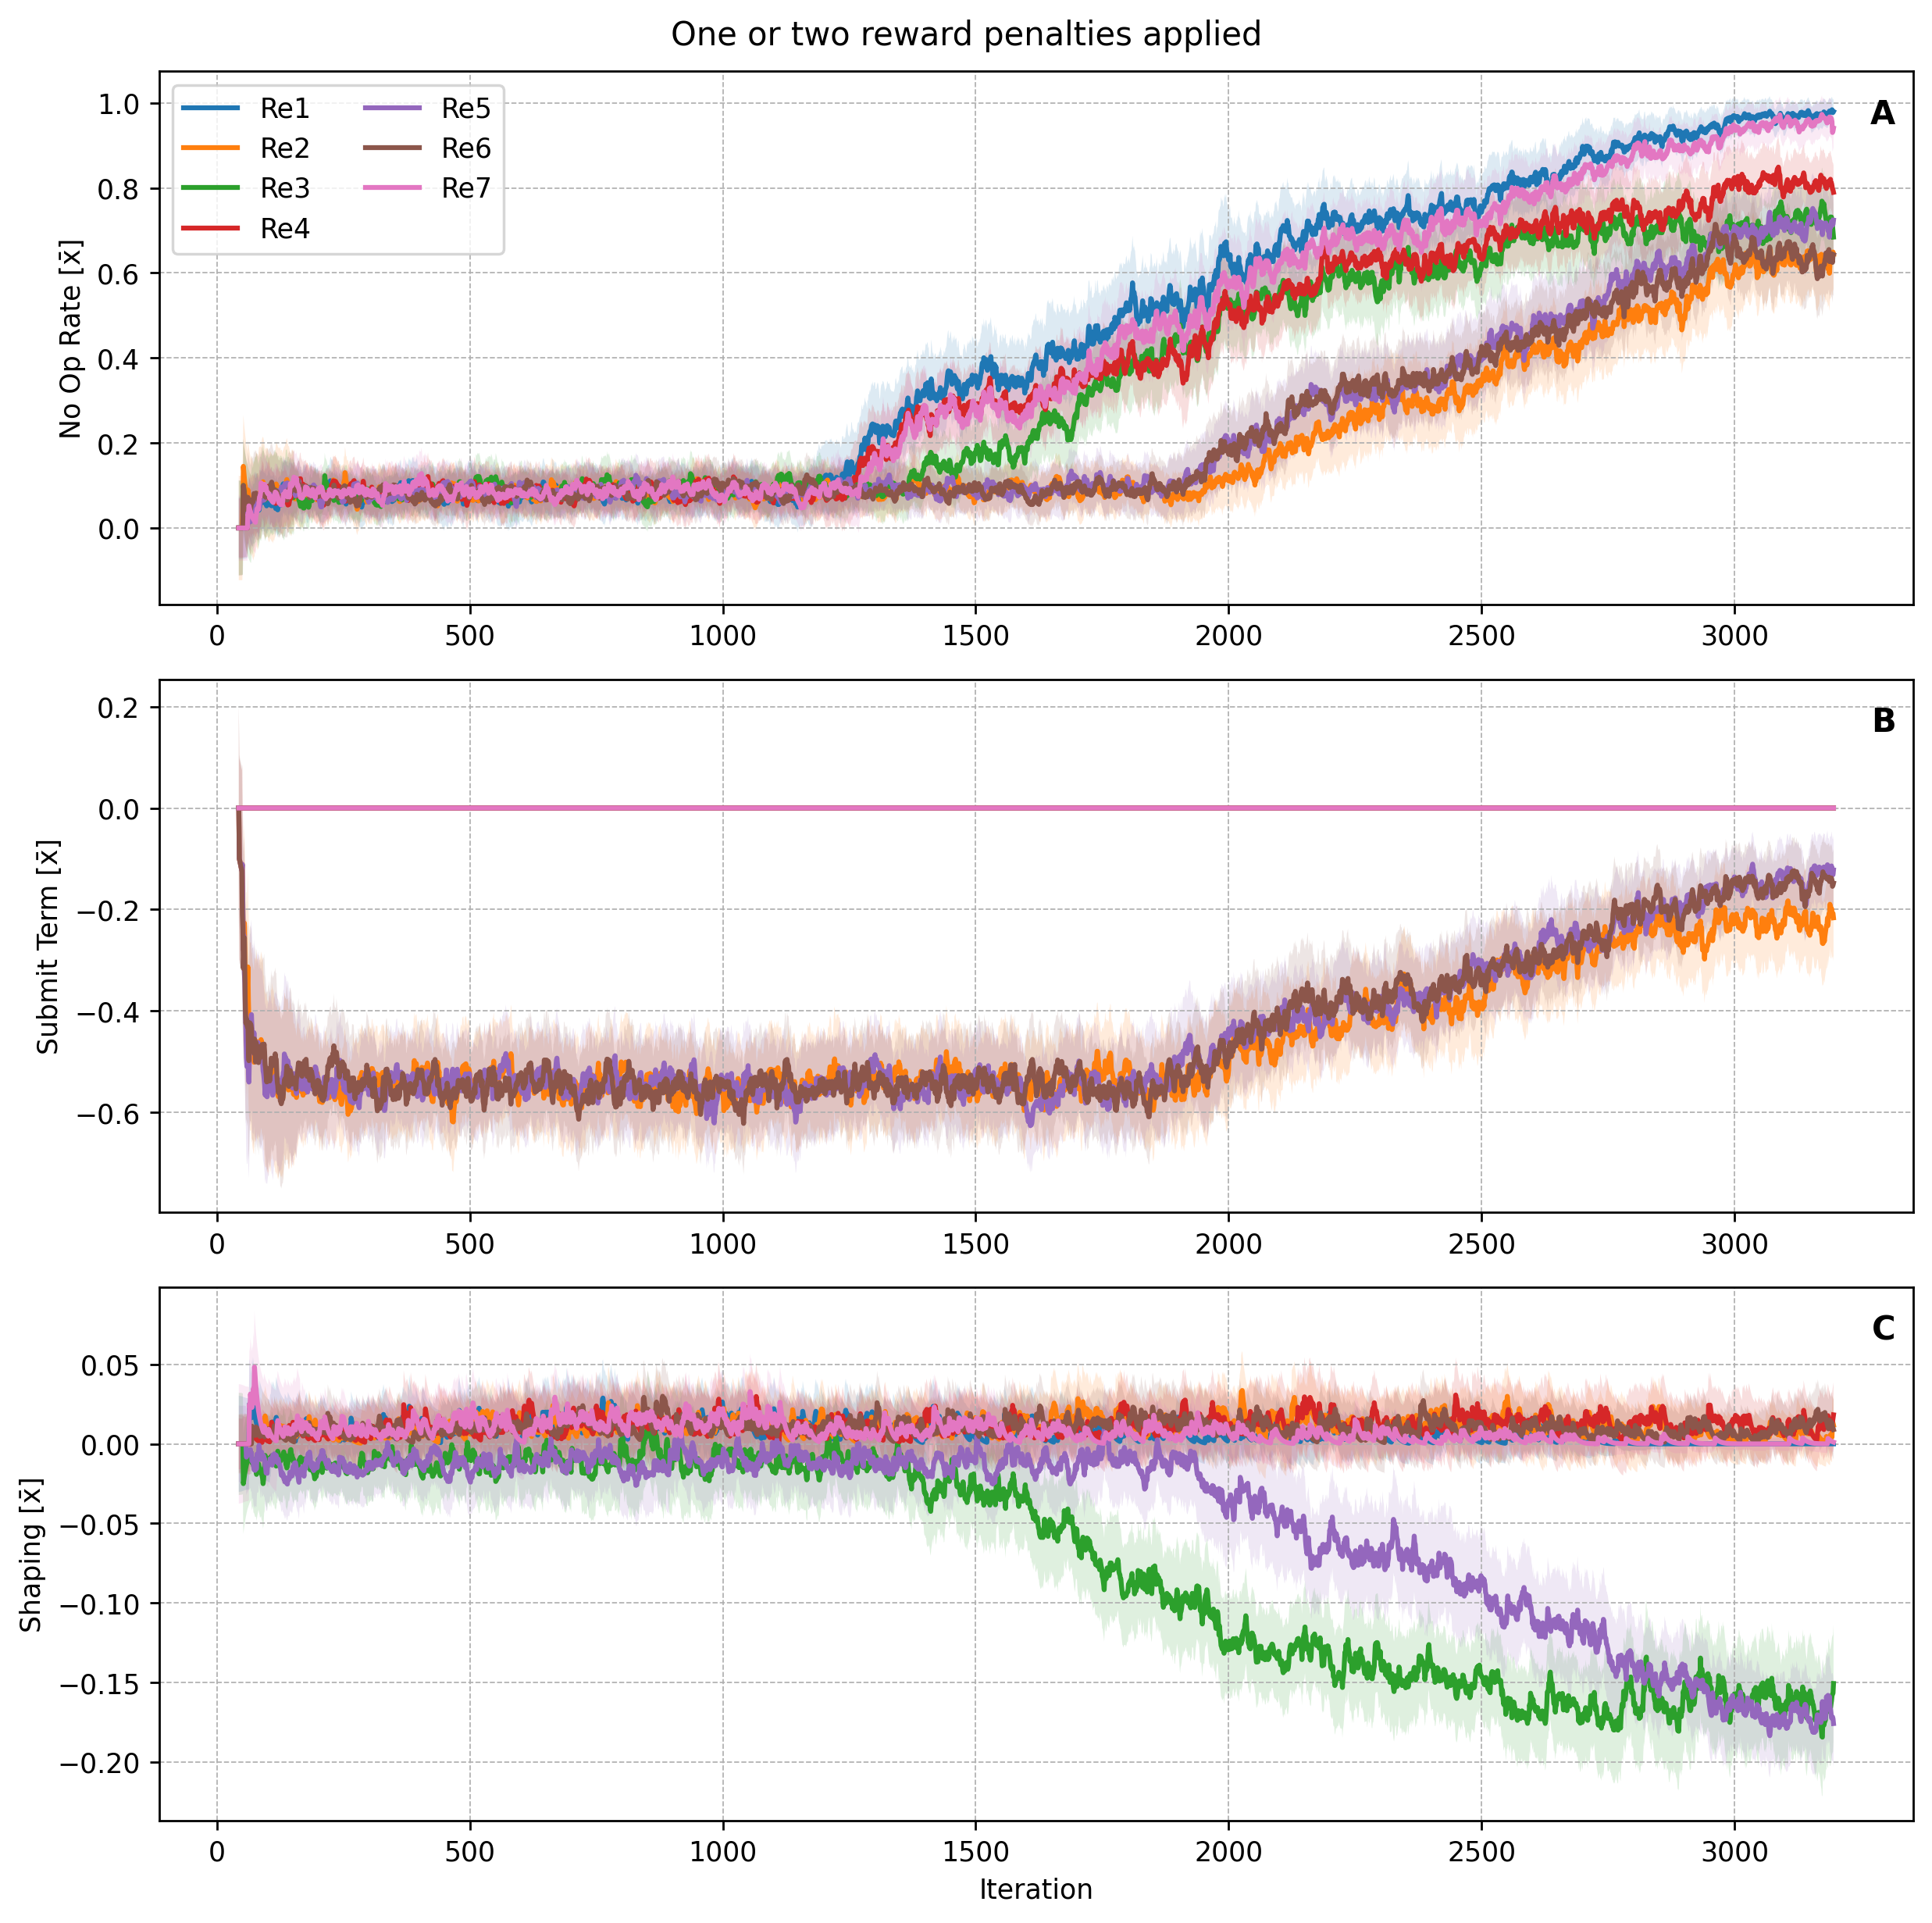

In [7]:
fig, ax = plt.subplots(3, 1, figsize=(10, 10), dpi=250)
ax = ax.flatten()
alpha = 0.1
plot_sclar(
    ax[0],
    df.where(df["scalar_key"] == "train_env_pixel_reward_no_op_mean").copy(),
    y_label="No Op Rate [x̄]",
    alpha=alpha,
    std_window=200,
    legend=True,
    annotation_letter="A",
    annotation_letter_loc="upper right",
)
plot_sclar(
    ax[1],
    df.where(df["scalar_key"] == "train_env_pixel_reward_submit_term_mean").copy(),
    y_label="Submit Term [x̄]",
    alpha=alpha,
    std_window=200,
    legend=False,
    annotation_letter="B",
    annotation_letter_loc="upper right",
)
plot_sclar(
    ax[2],
    df.where(df["scalar_key"] == "train_env_pixel_reward_shaping_mean").copy(),
    y_label="Shaping [x̄]",
    x_label="Iteration",
    alpha=alpha,
    std_window=200,
    legend=False,
    annotation_letter="C",
    annotation_letter_loc="upper right",
)

fig.suptitle("One or two reward penalties applied")
plt.tight_layout()
plt.show()

## Reward Experiments From 8 to 13

In [16]:
root = Path("checkpoints/rewards/8to13")
tag = "train/env/pixel_reward"
df = get_scalar_df(root, tag, "Re")
df["scalar_key"].unique()

array(['train_env_pixel_reward_no_op_mean',
       'train_env_pixel_reward_not_submit_term_mean',
       'train_env_pixel_reward_shaping_mean',
       'train_env_pixel_reward_submit_term_mean'], dtype=object)

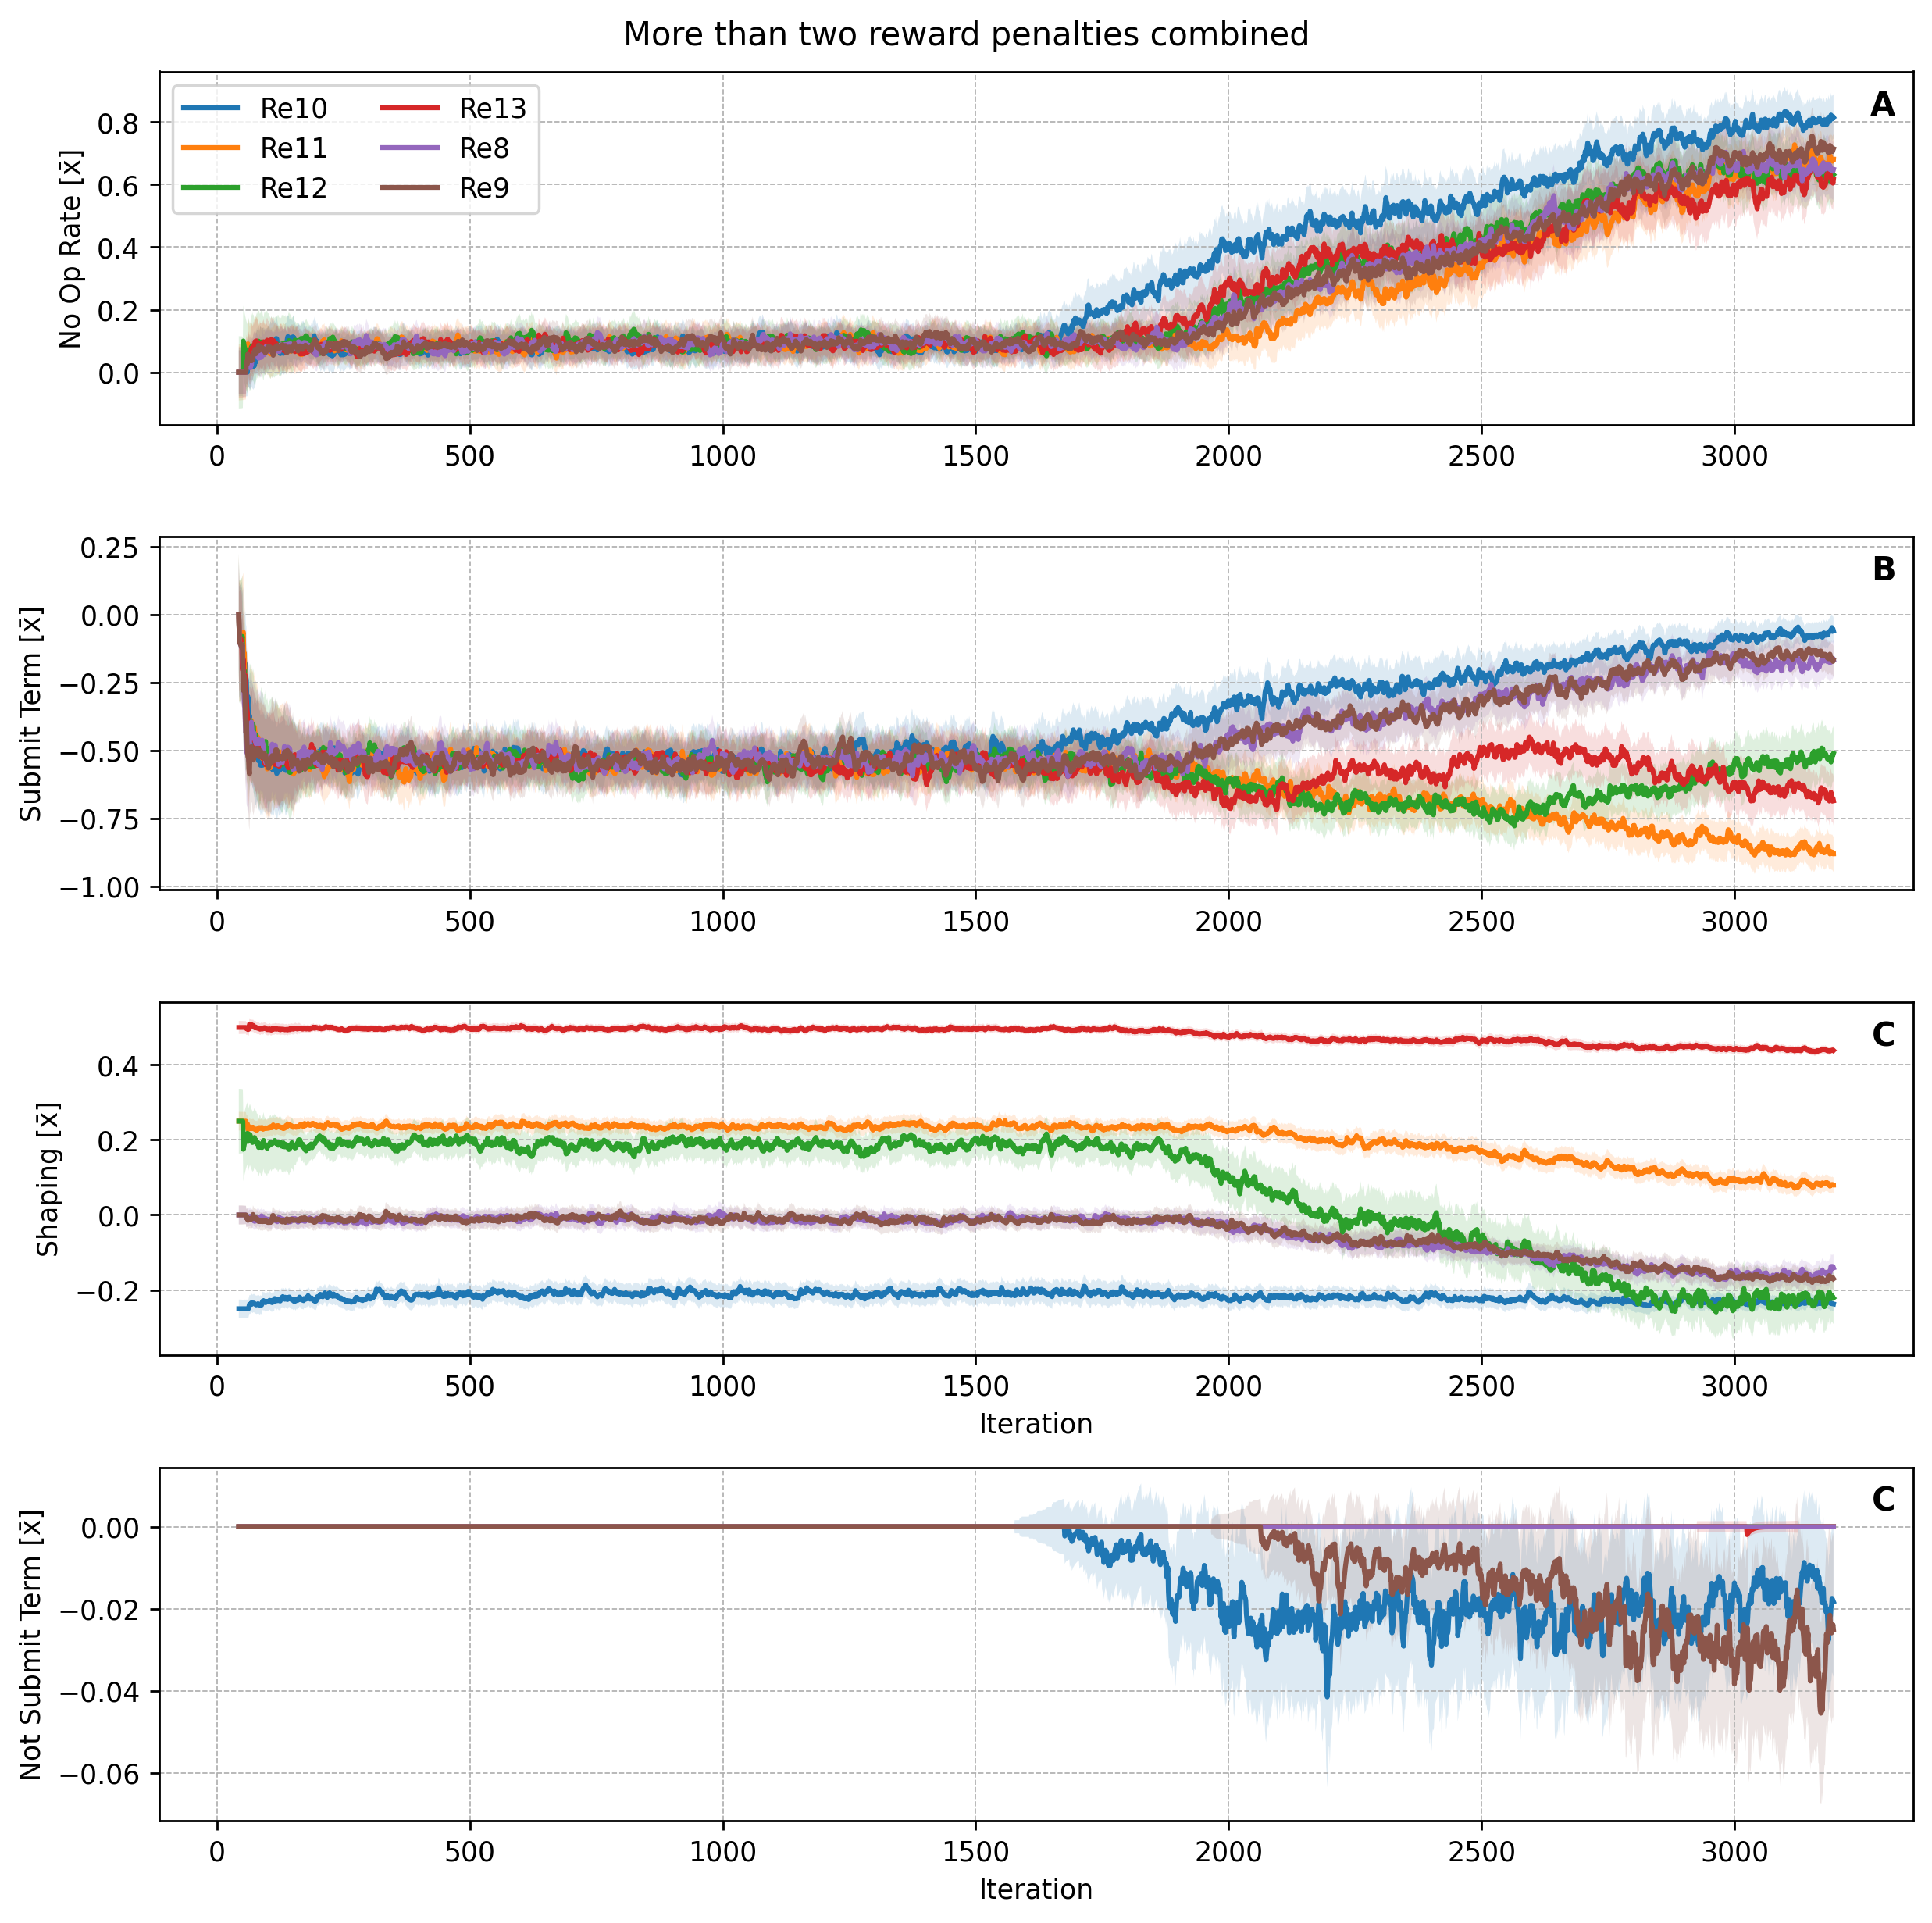

In [22]:
fig, ax = plt.subplots(4, 1, figsize=(10, 10), dpi=250)
ax = ax.flatten()
alpha = 0.1
plot_sclar(
    ax[0],
    df.where(df["scalar_key"] == "train_env_pixel_reward_no_op_mean").copy(),
    y_label="No Op Rate [x̄]",
    alpha=alpha,
    std_window=200,
    legend=True,
    annotation_letter="A",
    annotation_letter_loc="upper right",
)
plot_sclar(
    ax[1],
    df.where(df["scalar_key"] == "train_env_pixel_reward_submit_term_mean").copy(),
    y_label="Submit Term [x̄]",
    alpha=alpha,
    std_window=200,
    legend=False,
    annotation_letter="B",
    annotation_letter_loc="upper right",
)
plot_sclar(
    ax[2],
    df.where(df["scalar_key"] == "train_env_pixel_reward_shaping_mean").copy(),
    y_label="Shaping [x̄]",
    x_label="Iteration",
    alpha=alpha,
    std_window=200,
    legend=False,
    annotation_letter="C",
    annotation_letter_loc="upper right",
)
plot_sclar(
    ax[3],
    df.where(df["scalar_key"] == "train_env_pixel_reward_not_submit_term_mean").copy(),
    y_label="Not Submit Term [x̄]",
    x_label="Iteration",
    alpha=alpha,
    std_window=200,
    legend=False,
    annotation_letter="C",
    annotation_letter_loc="upper right",
)

fig.suptitle("More than two reward penalties combined")
plt.tight_layout()
plt.show()